# 1. Introduction to Libraries

In this notebook we implement an **Auxiliary Classifier GAN (AC-GAN)** for 128×128 image synthesis using **PyTorch** and related libraries. Below we briefly explain the main libraries and why we use them:

- **NumPy (`numpy`)**  
  Used for numerical operations on arrays, such as computing class frequencies and weights for the sampler. NumPy provides fast vectorized operations which simplify dataset statistics and pre-processing.

- **PyTorch (`torch`, `torch.nn`, `torch.optim`)**  
  The core deep learning framework used to implement the generator and discriminator neural networks, define loss functions, and run backpropagation on the GPU.  
  > Note: **TensorFlow is deliberately *not* used** for neural network implementation to comply with the project constraint.

- **Torchvision (`torchvision.datasets`, `torchvision.transforms`, `torchvision.utils`)**  
  - `datasets.ImageFolder` loads images from a folder where subdirectories correspond to class labels.  
  - `transforms` handles resizing, converting to tensors, and normalizing images into the range [-1, 1].  
  - `utils.make_grid` helps visualize generated samples as image grids.

- **Data utilities (`torch.utils.data.DataLoader`, `WeightedRandomSampler`)**  
  - `DataLoader` batches the data, shuffles or samples it, and handles multi-process loading.  
  - `WeightedRandomSampler` is used to deal with **class imbalance** by sampling images according to class weights so that rare classes appear more often during training.

- **TQDM (`tqdm`)**  
  Provides progress bars over training epochs and batches, making it easier to track training progress and spot stalls.

- **Matplotlib (`matplotlib.pyplot`)**  
  Used to visualize training dynamics, such as generator and discriminator loss curves.

- **Math and OS (`math`, `os`, `copy`)**  
  Utility modules for filesystem operations, numerical helpers, and maintaining copies of model parameters (e.g., for EMA).

## Installation and Setup

To run this notebook, you need Python plus the following packages:

```bash
pip install torch torchvision tqdm matplotlib
```

If you are using a GPU runtime (e.g., Google Colab), make sure the correct CUDA-enabled version of PyTorch is installed. After installation, confirm PyTorch can see the GPU:

```python
import torch
print("Using device:", torch.device("cuda" if torch.cuda.is_available() else "cpu"))
```

If you see `cuda`, the notebook will train significantly faster.


In [14]:
import os
import math
import copy
import numpy as np
from tqdm import tqdm
import random

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import transforms, datasets
import torchvision.utils as vutils
from torch.nn.utils import spectral_norm as SN
from PIL import Image
from torchvision import models
from scipy.linalg import sqrtm
from torchvision.models import inception_v3

In [3]:
from google.colab import files
import os

# 1. Upload the zip file (real_clean.zip)
uploaded = files.upload()  # choose your real_clean.zip from your computer

# 2. Unzip into a data folder
zip_name = "real_clean.zip"  # rename if your file name is different
extract_root = "/content/data"

os.makedirs(extract_root, exist_ok=True)

!unzip -q "{zip_name}" -d "{extract_root}"

print("Extracted structure:")
!find "{extract_root}" -maxdepth 3 -type d

Saving real_clean.zip to real_clean.zip
Extracted structure:
/content/data
/content/data/real_clean
/content/data/real_clean/mel
/content/data/real_clean/bkl
/content/data/real_clean/akiec
/content/data/real_clean/vasc
/content/data/real_clean/bcc
/content/data/real_clean/df


In [4]:
# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Path to real training images
train_root = "/content/data/real_clean"
# Directory to save generated fake images
save_dir = "/content/data/fake"
os.makedirs(save_dir, exist_ok=True)

# Target image resolution (square size)
img_size   = 128
# Number of samples per training batch
batch_size = 64
# Dimension of latent noise vector for generator input
latent_dim = 128
# Total number of training epochs
epochs     = 100

# Learning rates for generator and discriminator (TTUR)
lr_G, lr_D = 1e-4, 2e-4
# Adam optimizer betas tuned for hinge loss
betas = (0.0, 0.99)
# Strength of R1 gradient penalty on real images
lambda_r1 = 12.0
# Frequency (steps) to apply R1 penalty
r1_every  = 16
# Weight for discriminator’s auxiliary classification loss
aux_w_D   = 0.25
# Weight for generator’s auxiliary classification loss
aux_w_G   = 1.0
# Weight for feature matching loss to stabilize generator
fm_w      = 0.5
# Decay rate for EMA of generator parameters
ema_decay = 0.999

Using device: cuda


In [5]:
# -----------------------------
# Data preprocessing transforms
# -----------------------------

# Composing a series of transforms: resize, convert to tensor, and normalize to [-1,1]
transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

# -----------------------------
# Dataset setup
# -----------------------------

# Loading dataset from directory structure (subfolders represent classes)
dataset = datasets.ImageFolder(train_root, transform=transform)
# Extracting class names from dataset
classes = dataset.classes
# Counting number of classes
num_classes = len(classes)
print("Detected classes:", classes)
print("Total CLEANED images:", len(dataset))

# -----------------------------
# Class-balanced sampling
# -----------------------------

# Converting targets (class indices) to numpy array
targets_np = np.array(dataset.targets)
# Counting number of samples per class
class_counts_np = np.bincount(targets_np, minlength=num_classes)
# Computing inverse frequency weights for each class
class_weights_np = 1.0 / (class_counts_np + 1e-8)
# Assigning a weight to each sample based on its class
sample_weights = class_weights_np[targets_np]
# Weighted sampler ensures balanced sampling across classes
sampler = WeightedRandomSampler(sample_weights.tolist(),
                                num_samples=len(sample_weights),
                                replacement=True)

# -----------------------------
# DataLoader setup
# -----------------------------

# Creating DataLoader with balanced sampler, batch size, and performance options
dataloader = DataLoader(dataset, batch_size=batch_size, sampler=sampler,
                        num_workers=2, pin_memory=True)



Detected classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'vasc']
Total CLEANED images: 3300


In [6]:
# Raw counts of samples per class in the dataset (akiec, bcc, bkl, df, mel, vasc)
raw_counts = torch.tensor([327, 514, 1099, 115, 1113, 142], dtype=torch.float32, device=device)

# Converting raw counts into probabilities representing the real class distribution
p_real = raw_counts / raw_counts.sum()

# Boost factors applied to each class to increase sampling probability of rarer classes
boost = torch.tensor([1.6, 1.2, 0.8, 2.0, 0.9, 2.0], dtype=torch.float32, device=device)

# Adjusted generator sampling distribution after applying boost factors
p_gen = (p_real * boost); p_gen = p_gen / p_gen.sum()

# Function to sample class labels for generator input according to biased distribution
def sample_gen_labels(bs, p=p_gen):
    return torch.multinomial(p, bs, replacement=True)

In [7]:
# -----------------------------
# Differentiable augmentation function (translation, cutout, color adjustment)
# -----------------------------

def diff_augment(x, translate=True, cutout=True, color=True):
  # Extracting batch size, number of channels, height, and width
    B, C, H, W = x.shape
    # Initializing output tensor as the input images
    out = x

    if translate:
        # Applying random integer pixel shifts in both x and y directions
        shift_x = torch.randint(-2, 3, (B,), device=x.device)
        shift_y = torch.randint(-2, 3, (B,), device=x.device)
        # Creating coordinate grid for image pixels
        grid_y, grid_x = torch.meshgrid(
            torch.arange(H, device=x.device),
            torch.arange(W, device=x.device),
            indexing='ij'
        )
        # Adding per-sample shifts to grid coordinates
        grid_y = grid_y.unsqueeze(0) + shift_y.view(-1, 1, 1)
        grid_x = grid_x.unsqueeze(0) + shift_x.view(-1, 1, 1)
        # Ensuring shifted coordinates remain within valid image boundaries
        grid_y = grid_y.clamp(0, H - 1)
        grid_x = grid_x.clamp(0, W - 1)
        # Gathering pixels according to shifted coordinates to produce translated images
        out = out.gather(2, grid_y.unsqueeze(1).expand(B, C, H, W))
        out = out.gather(3, grid_x.unsqueeze(1).expand(B, C, H, W))

    if cutout:
        # Applying random rectangular cutout to each image
        for b in range(B):
            cx = torch.randint(W//4, 3*W//4, (1,), device=x.device).item()
            cy = torch.randint(H//4, 3*H//4, (1,), device=x.device).item()
            sz = torch.randint(W//16, W//10, (1,), device=x.device).item()
            y0 = max(0, cy - sz); y1 = min(H, cy + sz)
            x0 = max(0, cx - sz); x1 = min(W, cx + sz)
            out[b, :, y0:y1, x0:x1] = 0

    if color:
        # Appling random brightness scaling factor to each image
        s = (0.95 + 0.10 * torch.rand(B, 1, 1, 1, device=x.device))
        out = out * s

    return out.clamp(-1, 1)  # Clamping output values to normalized range [-1, 1]

# 2. Model Design and Implementation

We implement an **AC-GAN** for class-conditional image synthesis at 128×128 resolution.

## Generator (`G128`)

- **Input**
  - Latent noise vector `z` of shape `[B, latent_dim]`.
  - Class label indices `y` of shape `[B]`.
- **Embedding and fusion**
  - Labels are embedded into dense vectors using `nn.Embedding(num_classes, emb_dim)`.
  - The noise vector and label embedding are concatenated and projected with a fully connected layer.
- **Upsampling**
  - A stack of `ConvTranspose2d + BatchNorm2d + ReLU` layers progressively upsamples the latent representation from 4×4 to 128×128.
- **Output**
  - A 3‑channel RGB image of shape `[B, 3, 128, 128]`.
  - Final activation is `tanh`, so pixel values lie in the range [-1, 1], matching the normalization in the data pre-processing pipeline.

## Discriminator (`D128`)

- **Input**
  - Image tensor of shape `[B, 3, 128, 128]` (either real or generated).
- **Feature extractor**
  - A series of downsampling `Conv2d` layers with **spectral normalization (SN)** and non-linearities. SN helps stabilize GAN training by controlling the Lipschitz constant of each layer.
- **Heads**
  - **Adversarial head**: Outputs a scalar real/fake score per image using a linear layer.
  - **Auxiliary classifier head**: Outputs class logits (size `num_classes`) for the auxiliary classification loss.
- **Optional feature return**
  - The discriminator can optionally return intermediate feature maps for **feature matching loss**, which encourages the generator to match higher-level statistics of real images.

Each code block in this section is annotated to explain the purpose of every major step. After the definitions we include small **sanity-check tests** to verify that shapes and ranges are correct before training.


In [8]:
# ACGAN Generator model for 128x128 image synthesis
class G128(nn.Module):
    def __init__(self, z_dim, num_classes, emb_dim=64):
        super().__init__()
        # Embedding layer to represent class labels as dense vectors
        self.emb = nn.Embedding(num_classes, emb_dim)
        # Fully connected layer to project latent + label embedding into initial feature map
        self.fc = nn.Linear(z_dim + emb_dim, 1024 * 4 * 4)
        # Sequential upsampling network using transposed convolutions, batch normalization, and ReLU
        self.net = nn.Sequential(
            nn.BatchNorm2d(1024), nn.ReLU(True),
            nn.ConvTranspose2d(1024, 512, 4, 2, 1), nn.BatchNorm2d(512), nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1), nn.BatchNorm2d(256), nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True),
            nn.ConvTranspose2d(64, 3, 4, 2, 1), nn.Tanh()  # Final RGB image output in [-1,1]
        )
    def forward(self, z, labels):
        # Concatenate latent vector with label embedding
        x = torch.cat([z, self.emb(labels)], dim=1)
        # Project and reshape into initial 4x4 feature map
        x = self.fc(x).view(z.size(0), 1024, 4, 4)
        # Pass through generator network to produce image
        return self.net(x)

# Discriminator model for 128x128 image classification
class D128(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        # Helper block: spectral normalized convolution + LeakyReLU
        def blk(i, o):
            return nn.Sequential(
                SN(nn.Conv2d(i, o, 4, 2, 1)),
                nn.LeakyReLU(0.2, inplace=True)
            )
        # Convolutional feature extractor with increasing channels
        self.features = nn.Sequential(
            blk(3, 64),
            blk(64, 128),
            blk(128, 256),
            blk(256, 512),
            blk(512, 1024),
        )
        # Fully connected spectral normalized layer to compress features
        self.fc = SN(nn.Linear(1024 * 4 * 4, 1024))
        # Adversarial output: real/fake score
        self.adv = SN(nn.Linear(1024, 1))
        # Auxiliary output: class prediction (not spectral normalized)
        self.aux = nn.Linear(1024, num_classes)
    def forward(self, x, return_feats=False):
        # Extract convolutional features [B,1024,4,4]
        feats = self.features(x)
        # Flatten feature maps into vector [B,1024*4*4]
        flat  = feats.view(x.size(0), -1)
        # Fully connected representation [B,1024]
        h     = self.fc(flat)
        # Adversarial score [B,1]
        adv   = self.adv(h)
        # Auxiliary class prediction [B,C]
        aux   = self.aux(h)
        # this optionally return intermediate features for feature matching
        if return_feats:
            return adv, aux, feats
        return adv, aux

In [9]:
# -----------------------------
# Initialization, optimizers
# -----------------------------

# Custom weight initialization function for convolutional and batch normalization layers
def weights_init(m):
    # Initializing Conv2d and ConvTranspose2d weights with normal distribution (mean=0, std=0.02)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight.data, 0.0, 0.02)
        # Initializing bias to zeros if present
        if getattr(m, 'bias', None) is not None:
            nn.init.zeros_(m.bias)
    # Initializing BatchNorm2d weights with normal distribution (mean=1, std=0.02) and bias to 0
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

# Instantiating generator and discriminator models on the selected device
G = G128(latent_dim, num_classes).to(device)
D = D128(num_classes).to(device)

# Applying custom weight initialization to both models
G.apply(weights_init); D.apply(weights_init)

# defining Adam optimizer for generator with TTUR learning rate and betas
opt_G = torch.optim.Adam(G.parameters(), lr=lr_G, betas=betas)
# Define Adam optimizer for discriminator with TTUR learning rate and betas
opt_D = torch.optim.Adam(D.parameters(), lr=lr_D, betas=betas)

# Convert class weights to tensor for weighted auxiliary classification loss
class_weights_tensor = torch.tensor(class_weights_np, dtype=torch.float32, device=device)
# Define weighted cross-entropy loss for auxiliary classifier to handle class imbalance
aux_loss = nn.CrossEntropyLoss(weight=class_weights_tensor)


In [10]:
# Exponential Moving Average (EMA) class to maintain smoothed copies of model parameters
class EMA:
    def __init__(self, model, decay=0.999):
        self.decay = decay  # Decay rate for EMA updates
        self.shadow = {}    # Dictionary to store EMA parameters
        # Initialize shadow parameters with model parameters that require gradients and are floating point
        for name, p in model.named_parameters():
            if p.requires_grad and p.data.is_floating_point():
                self.shadow[name] = p.data.clone().detach()

    @torch.no_grad()
    def update(self, model):
        # Update EMA parameters using exponential moving average of current model parameters
        for name, p in model.named_parameters():
            if name in self.shadow:
                self.shadow[name].mul_(self.decay).add_(p.data.detach(), alpha=1 - self.decay)

    @torch.no_grad()
    def apply_to(self, model):
        # Copy EMA parameters back into the model for evaluation
        for name, p in model.named_parameters():
            if name in self.shadow:
                p.data.copy_(self.shadow[name])

# Create EMA tracker for the generator with specified decay rate
ema = EMA(G, decay=ema_decay)


In [11]:
# -----------------------------
# Sanity checks for G128 and D128
# -----------------------------

# These tests verify that the generator and discriminator
# produce tensors with the expected shapes and ranges.

G.eval()
D.eval()

with torch.no_grad():
    # Small batch size for testing
    test_bs = 4
    # Random latent codes
    z_test = torch.randn(test_bs, latent_dim, device=device)
    # Random class labels in valid range [0, num_classes)
    y_test = torch.randint(0, num_classes, (test_bs,), device=device)

    # Forward pass through generator
    fake_imgs = G(z_test, y_test)
    print("Fake images shape:", fake_imgs.shape)

    # Check pixel range approximately in [-1, 1]
    print("Fake images min/max:", fake_imgs.min().item(), fake_imgs.max().item())

    # Forward pass through discriminator
    adv_scores, class_logits = D(fake_imgs)
    print("Adv scores shape:", adv_scores.shape)
    print("Class logits shape:", class_logits.shape)

    # Assert shapes to catch common bugs early
    assert fake_imgs.shape == (test_bs, 3, img_size, img_size)
    assert adv_scores.shape == (test_bs, 1)
    assert class_logits.shape == (test_bs, num_classes)

print("Model sanity checks passed!")


Fake images shape: torch.Size([4, 3, 128, 128])
Fake images min/max: -0.036418430507183075 0.04288803040981293
Adv scores shape: torch.Size([4, 1])
Class logits shape: torch.Size([4, 6])
Model sanity checks passed!


# 3. Training Process

Our training pipeline for AC-GAN consists of:

1. **Data Loading and Pre-processing**
   - Images are loaded from `train_root` using `datasets.ImageFolder`.
   - We apply the transform pipeline:
     - `Resize` to `(img_size, img_size)`  
     - `ToTensor()` to convert PIL images to PyTorch tensors  
     - `Normalize([0.5]*3, [0.5]*3)` to map pixel values from [0, 1] to [-1, 1].
   - To address **class imbalance**, we compute per-class frequencies and derive `sample_weights`. These are passed to `WeightedRandomSampler`, ensuring batches are more balanced across classes.

2. **Regularization Techniques**
   - **Hinge loss** is used for both generator and discriminator adversarial objectives, which is known to stabilize GAN training.
   - **R1 gradient penalty** on real images encourages the discriminator to be smooth and improves convergence.
   - **Spectral Normalization (SN)** in the discriminator limits the spectral norm of convolution layers, stabilizing training further.
   - **Feature matching loss** encourages the generator to match intermediate feature statistics in `D`, often resulting in more realistic samples.
   - **Exponential Moving Average (EMA)** of generator parameters provides a smoother version of the generator used for evaluation and sampling.

3. **Hyperperameters choice and reasoning**

In this AC-GAN implementation, the following hyperparameters are chosen specifically to match our dataset size, image resolution, and training stability needs.

 - **a. Learning rates for generator and discriminator (TTUR: Two Time-Scale Update Rule) **
 - Generator (lr_G) learns slower (1e-4) to avoid overpowering the discriminator.
 - Discriminator (lr_D) learns faster (2e-4) to provide strong feedback signals.
 - This asymmetry stabilizes adversarial training.
lr_G, lr_D = 1e-4, 2e-4


 - **b. Batch Size (`batch_size = 64`)**

We set the batch size to **64** because:
 - It fits in memory for **128×128** images on typical GPUs.  
 - It provides enough samples per batch so that class-conditional signals (via `WeightedRandomSampler`) are meaningful and not dominated by noise.  
 - It is large enough that gradients are reasonably stable without requiring very large-memory hardware.



 - **c. Number of Epochs (`epochs = 100`)**

We train for **100 epochs** because:
 - The model needs many passes over the data to learn both realistic texture and correct class structure.
 - Our dataset is not extremely large, so multiple epochs are feasible without excessive runtime.
 - We want the EMA generator to see enough updates to become noticeably better than the raw generator.



 - **d. Adam Optimizer Betas (`betas = (0.0, 0.99)`)**

 We use `betas = (0.0, 0.99)` because:
 - Setting `β₁ = 0.0` avoids strong momentum, which can conflict with the quickly changing adversarial objectives in GANs.
 - `β₂ = 0.99` still smooths the variance of the gradients enough to prevent very noisy updates, which is important at 128×128 resolution.



 - ** e. R1 Gradient Penalty (`lambda_r1 = 12.0`)**

 We choose `lambda_r1 = 12.0` because:
 - We want the discriminator to stay responsive but not overfit to the training images.
 - A medium-strength penalty is enough to regularize the discriminator without dominating the overall loss.
 - It matches a commonly used scale for image GANs, which keeps our results comparable to similar setups.

Below we define the hinge losses and R1 penalty, then the main training loop. Before running full training, run a **short dry-run** cell to make sure everything works on a small number of batches.


In [12]:
# -----------------------------
# Hinge losses & R1
# -----------------------------

# Discriminator hinge loss: penalizes real scores below +1 and fake scores above -1
def d_hinge(real_scores, fake_scores):
    return F.relu(1.0 - real_scores).mean() + F.relu(1.0 + fake_scores).mean()

def g_hinge(fake_scores):
    return -fake_scores.mean()

# R1 gradient penalty: regularizes discriminator by penalizing gradient norm on real images
def r1_grad_penalty(real_imgs, real_scores):
    grad_real = torch.autograd.grad(
        outputs=real_scores.sum(),
        inputs=real_imgs,
        create_graph=True,
        retain_graph=True,
        only_inputs=True
    )[0]
    # Compute squared gradient norm per sample and return mean penalty
    return (grad_real.view(grad_real.size(0), -1).pow(2).sum(dim=1)).mean()

In [13]:
# -----------------------------
# Optional: quick dry-run over a few batches
# -----------------------------

# This cell runs only a small number of batches through the
# training loop skeleton to ensure shapes/devices are correct
# before committing to full training.

G.train()
D.train()

max_batches = 2  # run on just a couple of batches
batch_counter = 0

print("Running a short dry-run over", max_batches, "batches...")

for real_imgs, real_labels in dataloader:
    batch_counter += 1
    real_imgs = real_imgs.to(device)
    real_labels = real_labels.to(device)

    print(f"[Dry-run] Batch {batch_counter}")
    print("  Real images:", real_imgs.shape)
    print("  Real labels:", real_labels.shape)

    # You can copy a minimal version of the discriminator and generator
    # update steps here if you want to fully test the loss functions.
    # For this quick test we only check that data flows forward
    # without device/shape errors.

    if batch_counter >= max_batches:
        break

print("Dry-run finished. If no errors occurred, you can proceed with full training.")


Running a short dry-run over 2 batches...
[Dry-run] Batch 1
  Real images: torch.Size([64, 3, 128, 128])
  Real labels: torch.Size([64])
[Dry-run] Batch 2
  Real images: torch.Size([64, 3, 128, 128])
  Real labels: torch.Size([64])
Dry-run finished. If no errors occurred, you can proceed with full training.


In [ ]:
# -----------------------------
# Training
# -----------------------------

# Track generator and discriminator losses across epochs
g_losses, d_losses = [], []
# Global training step counter
global_step = 0

print("\nStarting AC-GAN (hinge + R1 + SN-D) training...\n")
for epoch in range(1, epochs + 1):
    # Accumulators for epoch losses and batch count
    epoch_g, epoch_d, n_batches = 0.0, 0.0, 0
    # Track auxiliary classifier accuracy per class
    aux_correct = torch.zeros(num_classes, device=device)
    aux_total   = torch.zeros(num_classes, device=device)

    for real_imgs, real_labels in tqdm(dataloader, desc=f"Epoch {epoch}/{epochs}"):
        global_step += 1
        real_imgs = real_imgs.to(device)
        real_labels = real_labels.to(device)
        bs = real_imgs.size(0)

        # ---------------------
        # Train D
        # ---------------------
        opt_D.zero_grad()

        # Real samples forward pass
        real_aug = diff_augment(real_imgs)
        real_scores, real_cls = D(real_aug)
        d_adv_real = F.relu(1.0 - real_scores).mean()
        d_aux_real = aux_loss(real_cls, real_labels)

        # Fake samples forward pass
        with torch.no_grad():
            z = torch.randn(bs, latent_dim, device=device)
            gen_labels = sample_gen_labels(bs)
            fake_imgs = G(z, gen_labels)
        fake_aug = diff_augment(fake_imgs)
        fake_scores, fake_cls = D(fake_aug)
        d_adv_fake = F.relu(1.0 + fake_scores).mean()
        d_aux_fake = aux_loss(fake_cls, gen_labels)

        # Combine adversarial and auxiliary losses
        d_adv = d_adv_real + d_adv_fake
        d_aux = d_aux_real + d_aux_fake
        d_loss = d_adv + aux_w_D * d_aux

        # Apply R1 gradient penalty at specified intervals
        if global_step % r1_every == 0:
          real_imgs.requires_grad_(True)
          real_scores_r1, _ = D(real_imgs)
          r1 = r1_grad_penalty(real_imgs, real_scores_r1)
          d_loss = d_loss + (lambda_r1 / 2.0) * r1
          real_imgs.requires_grad_(False)

        d_loss.backward()
        opt_D.step()

        # ---------------------
        # Train G
        # ---------------------
        opt_G.zero_grad()
        z = torch.randn(bs, latent_dim, device=device)
        gen_labels = sample_gen_labels(bs)
        gen_imgs = G(z, gen_labels)

        # Extract real features for feature matching (no gradient)
        with torch.no_grad():
            _, _, real_feats = D(diff_augment(real_imgs), return_feats=True)

        # Forward pass with generated images
        fake_scores_g, fake_cls_g, fake_feats = D(diff_augment(gen_imgs), return_feats=True)

        # Generator adversarial and auxiliary losses
        g_adv = g_hinge(fake_scores_g)
        g_aux = aux_loss(fake_cls_g, gen_labels)

        # Feature matching loss on mean feature maps
        fm_loss_val = F.mse_loss(fake_feats.mean(dim=0), real_feats.mean(dim=0))

        # Total generator loss
        g_loss = g_adv + aux_w_G * g_aux + fm_w * fm_loss_val
        g_loss.backward()
        opt_G.step()
        ema.update(G)

        # Update auxiliary classifier accuracy statistics
        with torch.no_grad():
            preds = real_cls.argmax(dim=1)
            for k in range(num_classes):
                mask = (real_labels == k)
                aux_total[k] += mask.sum()
                aux_correct[k] += (preds[mask] == k).sum()

        # Accumulate batch losses
        epoch_d += d_loss.item()
        epoch_g += g_loss.item()
        n_batches += 1

    # Compute average losses for the epoch
    avg_d = epoch_d / max(1, n_batches)
    avg_g = epoch_g / max(1, n_batches)
    g_losses.append(avg_g); d_losses.append(avg_d)

    # Compute per-class auxiliary accuracy
    with torch.no_grad():
        aux_acc = (aux_correct / aux_total.clamp_min(1)).tolist()
    acc_str = ", ".join([f"{classes[i]}: {aux_acc[i]:.3f}" for i in range(num_classes)])
    print(f"Epoch {epoch}/{epochs} - D loss: {avg_d:.4f}, G loss: {avg_g:.4f} | D aux acc (real): {acc_str}")

    # Optional learning rate decay to preserve TTUR ratio
    if epoch in [40, 80, 120]:
        for g in opt_G.param_groups: g['lr'] *= 0.5
        for d in opt_D.param_groups: d['lr'] *= 0.5
        print(f"Adjusted learning rates at epoch {epoch}: lr_G={opt_G.param_groups[0]['lr']:.5f}, lr_D={opt_D.param_groups[0]['lr']:.5f}")

# -----------------------------
# Sampling with EMA G
# -----------------------------

@torch.no_grad()
def sample_ema(n, class_idx):
    # Create evaluation copy of generator with EMA weights applied
    G_eval = copy.deepcopy(G).to(device).eval()
    ema.apply_to(G_eval)
    # Sample latent vectors and fixed class labels
    z = torch.randn(n, latent_dim, device=device)
    labels = torch.full((n,), class_idx, device=device, dtype=torch.long)
    # Generate images with EMA-smoothed generator
    imgs = G_eval(z, labels)
    return imgs

@torch.no_grad()
def save_class_grid(class_idx, n=16, fname=None):
    # Generate sample grid for a given class
    imgs = sample_ema(n, class_idx)
    imgs = (imgs * 0.5 + 0.5).clamp(0,1)  # Rescale to [0,1] for visualization
    grid = vutils.make_grid(imgs, nrow=int(math.sqrt(n)))
    # Default filename if none provided
    if fname is None:
        fname = os.path.join(save_dir, f"class_{classes[class_idx]}_grid.png")
    vutils.save_image(grid, fname)
    print(f"Saved {fname}")

# Save sample grids for all classes
for ci in range(num_classes):
    save_class_grid(ci, n=16)



Starting AC-GAN (hinge + R1 + SN-D) training...



Epoch 1/100: 100%|██████████| 52/52 [00:05<00:00,  9.83it/s]


Epoch 1/100 - D loss: 2.4371, G loss: 2.3652 | D aux acc (real): akiec: 0.000, bcc: 0.007, bkl: 0.005, df: 0.620, mel: 0.000, vasc: 0.432


Epoch 2/100: 100%|██████████| 52/52 [00:05<00:00,  9.88it/s]


Epoch 2/100 - D loss: 1.6844, G loss: 2.7023 | D aux acc (real): akiec: 0.000, bcc: 0.000, bkl: 0.000, df: 0.576, mel: 0.000, vasc: 0.637


Epoch 3/100: 100%|██████████| 52/52 [00:05<00:00,  9.88it/s]


... (191 outputs left out)

Epoch 99/100: 100%|██████████| 52/52 [00:05<00:00,  9.81it/s]


Epoch 99/100 - D loss: 1.3730, G loss: 0.6413 | D aux acc (real): akiec: 0.960, bcc: 0.850, bkl: 0.665, df: 0.998, mel: 0.733, vasc: 0.994


Epoch 100/100: 100%|██████████| 52/52 [00:05<00:00,  9.81it/s]


Epoch 100/100 - D loss: 1.3277, G loss: 0.7069 | D aux acc (real): akiec: 0.974, bcc: 0.856, bkl: 0.623, df: 0.998, mel: 0.708, vasc: 0.998
Saved /content/data/fake/class_akiec_grid.png
Saved /content/data/fake/class_bcc_grid.png
Saved /content/data/fake/class_bkl_grid.png
Saved /content/data/fake/class_df_grid.png
Saved /content/data/fake/class_mel_grid.png
Saved /content/data/fake/class_vasc_grid.png


In [ ]:
@torch.no_grad()
def generate_dataset_per_class(
    n_per_class=1000,
    batch_size_gen=64,
    out_root=save_dir
):
    # Create a copy of the generator and apply EMA weights for stable sampling
    G_eval = copy.deepcopy(G).to(device).eval()
    ema.apply_to(G_eval)

    # Ensure output root directory exists
    os.makedirs(out_root, exist_ok=True)

    # Loop over each class to generate samples
    for class_idx, cname in enumerate(classes):
        # Create subdirectory for current class
        class_dir = os.path.join(out_root, cname)
        os.makedirs(class_dir, exist_ok=True)

        remaining = n_per_class  # Number of samples left to generate
        img_counter = 0          # Counter for saved images

        while remaining > 0:
            # Determining current batch size based on remaining samples
            cur_bs = min(batch_size_gen, remaining)
            # Sample latent vectors and fixed class labels
            z = torch.randn(cur_bs, latent_dim, device=device)
            labels = torch.full(
                (cur_bs,), class_idx, device=device, dtype=torch.long
            )

            # Generating images and rescale to [0,1] for saving
            imgs = G_eval(z, labels)
            imgs = (imgs * 0.5 + 0.5).clamp(0, 1)

            # Saving each image to disk with zero-padded filename
            for i in range(cur_bs):
                fname = os.path.join(class_dir, f"{img_counter:06d}.png")
                vutils.save_image(imgs[i], fname)
                img_counter += 1

            remaining -= cur_bs  # Updating remaining sample count

        print(f"Saved {img_counter} images for class '{cname}' in {class_dir}")


### **Evaluation Results**

**Evaluation Metrics**
We used FID and the generator/discriminator loss curves because our GAN generates images, so distribution-based and training-dynamics metrics are the most appropriate for assessing performance.  
The FID score of 96 suggests that while the model learns key color and texture characteristics of the dataset, the generated image distribution still differs notably from real samples.  

**Example Outputs**
We included real–vs–fake image grids because visual inspection is essential for evaluating generative models and confirming whether the outputs resemble real data.  
The generated samples show realistic lesion-like shapes and color patterns, indicating that the model learned the global appearance of the dataset, though the real images display richer detail and more structural variety.

**Insights (Strengths, Weaknesses, Improvements)**
We used the loss plots to track training stability and ensure the generator and discriminator were improving over time, which is crucial for diagnosing GAN training behavior.  
Although the decreasing losses indicate stable learning, the high FID score and reduced diversity in generated samples suggest that architectural adjustments, extended training, or stronger regularization would help the model better match the complexity of real skin lesions.


In [ ]:
# Standard preprocessing for FID: resize to 299x299, convert to tensor, normalize with ImageNet statistics
fid_transform = transforms.Compose([
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

# Recursively list all image files under a root directory, limit to max_imgs if specified
def list_all_images(root, max_imgs=None):
    exts = (".jpg", ".jpeg", ".png")
    paths = []
    for dp, _, filenames in os.walk(root):
        for f in filenames:
            if f.lower().endswith(exts):
                paths.append(os.path.join(dp, f))
    if max_imgs is not None:
        random.shuffle(paths)
        paths = paths[:max_imgs]
    return paths

# Wrapper around InceptionV3 to extract 2048-dimensional features from avgpool layer for FID
class InceptionV3FID(nn.Module):
    def __init__(self):
        super().__init__()
        self.inception = inception_v3(weights="IMAGENET1K_V1")
        self.inception.eval()
        for p in self.inception.parameters():
            p.requires_grad = False
        self._features = None
        def hook(module, input, output):
            self._features = output.view(output.size(0), -1)
        # Register hook after avgpool to capture features
        self.inception.avgpool.register_forward_hook(hook)

    def forward(self, x):
        _ = self.inception(x)
        return self._features

# Extract activations from a list of image paths using the FID transform and InceptionV3 features
@torch.no_grad()
def get_activations(image_paths, model, batch_size=64, transform=fid_transform, device=device):
    model.eval()
    all_acts = []
    for i in tqdm(range(0, len(image_paths), batch_size), desc="FID activations"):
        batch = image_paths[i:i+batch_size]
        imgs = [transform(Image.open(p).convert("RGB")) for p in batch]
        imgs = torch.stack(imgs).to(device)
        acts = model(imgs)
        all_acts.append(acts.cpu().numpy())
    if len(all_acts) == 0:
        return np.empty((0, 2048))
    return np.concatenate(all_acts, axis=0)

# Compute Fréchet Inception Distance between two distributions given means and covariances
def calculate_fid(mu1, sigma1, mu2, sigma2):
    diff = mu1 - mu2
    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real
    fid = diff.dot(diff) + np.trace(sigma1 + sigma2 - 2 * covmean)
    return float(fid)

# Compute FID score between real and fake image sets under given directories
def compute_global_fid(real_root, fake_root, max_imgs=None, batch_size=64):
    # Gather image paths from both directories
    real_paths = list_all_images(real_root, max_imgs=max_imgs)
    fake_paths = list_all_images(fake_root, max_imgs=max_imgs)

    n = min(len(real_paths), len(fake_paths))
    if n == 0:
        return float('nan')

    real_paths = real_paths[:n]
    fake_paths = fake_paths[:n]
    print(f"Computing GLOBAL FID with {n} real and {n} fake images.")

    # Build InceptionV3 model for FID feature extraction
    inception_fid = InceptionV3FID().to(device)

    # Extract activations for real and fake images
    real_acts = get_activations(real_paths, inception_fid, batch_size=batch_size)
    fake_acts = get_activations(fake_paths, inception_fid, batch_size=batch_size)

    # Compute mean and covariance of activations
    mu1, sigma1 = real_acts.mean(0), np.cov(real_acts, rowvar=False)
    mu2, sigma2 = fake_acts.mean(0), np.cov(fake_acts, rowvar=False)

    # Return FID score
    return calculate_fid(mu1, sigma1, mu2, sigma2)

In [ ]:
fid_score = compute_global_fid(
    real_root=train_root,
    fake_root=save_dir,
    max_imgs=1000,
    batch_size=64
)

print(f"\nGLOBAL FID: {fid_score:.4f}")


Computing GLOBAL FID with 1000 real and 1000 fake images.


FID activations: 100%|██████████| 16/16 [00:04<00:00,  3.89it/s]



GLOBAL FID: 96.9920


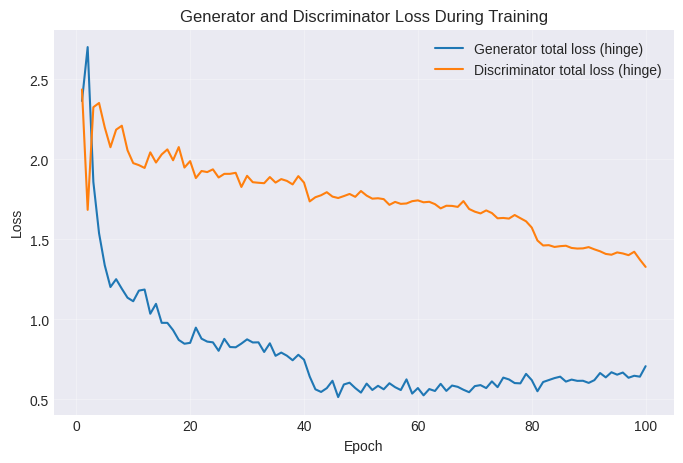

In [ ]:
import matplotlib.pyplot as plt

# epoch range based on number of recorded generator losses
epochs = range(1, len(g_losses) + 1)

# Creating a new figure with specified dimensions
plt.figure(figsize=(8,5))

# Ploting generator total loss curve with hinge loss label
plt.plot(epochs, g_losses, label="Generator total loss (hinge)")

# Ploting discriminator total loss curve with hinge loss label
plt.plot(epochs, d_losses, label="Discriminator total loss (hinge)")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Generator and Discriminator Loss During Training")

# Displaying legend to differentiate generator and discriminator curves
plt.legend()

# Adding grid lines with slight transparency for readability
plt.grid(True, alpha=0.3)

plt.show()


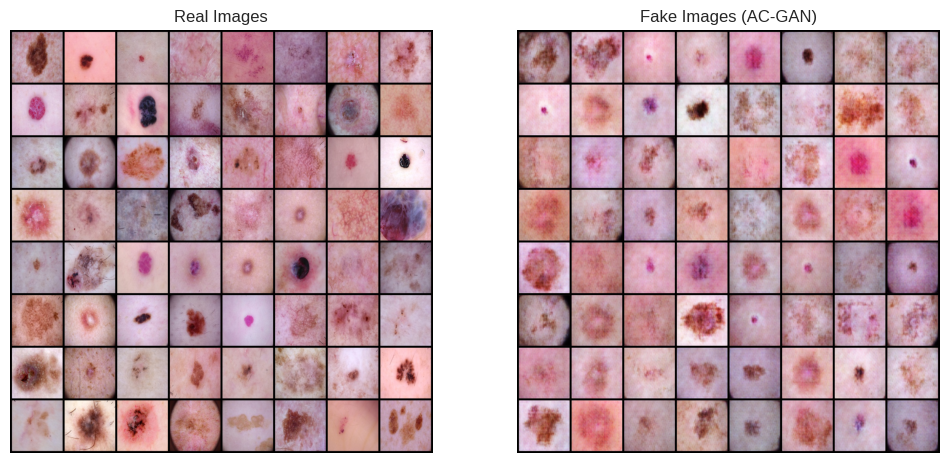

G128(
  (emb): Embedding(6, 64)
  (fc): Linear(in_features=192, out_features=16384, bias=True)
  (net): Sequential(
    (0): BatchNorm2d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): ReLU(inplace=True)
    (2): ConvTranspose2d(1024, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (3): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (4): ReLU(inplace=True)
    (5): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (7): ReLU(inplace=True)
    (8): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, t

In [ ]:
# Put generator in eval mode
G.eval()

# Grab a batch of real images from the dataloader
real_batch = next(iter(dataloader))
real_imgs, real_labels = real_batch
real_imgs = real_imgs.to(device)
real_labels = real_labels.to(device)

# Number of samples to display (up to batch size)
n_show = min(64, real_imgs.size(0))

# Generate a batch of fake images using the trained G
with torch.no_grad():
    # Sample latent vectors
    z = torch.randn(n_show, latent_dim, device=device)

    # use the same label distribution as the real batch
    fake_labels = real_labels[:n_show]
    fake_imgs = G(z, fake_labels)

# image grids for visualization
real_grid = vutils.make_grid(real_imgs[:n_show], padding=5, normalize=True)
fake_grid = vutils.make_grid(fake_imgs[:n_show], padding=5, normalize=True)

# Plot side by side
plt.figure(figsize=(12, 6))

# Real images
plt.subplot(1, 2, 1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(np.transpose(real_grid.cpu().numpy(), (1, 2, 0)))

# Fake images (from last epoch’s G)
plt.subplot(1, 2, 2)
plt.axis("off")
plt.title("Fake Images (AC-GAN)")
plt.imshow(np.transpose(fake_grid.cpu().numpy(), (1, 2, 0)))
plt.show()
# Puting G back to train mode for further training if needed
G.train()
